# SmartEgg Fase 3 · Detección de anomalías (Bloque A)

Pipeline completo: histórico de la Fase 2 → exploración → limpieza y features → entrenamiento → evaluación → modelo guardado para `ml/service.py`.

**Fuente:** colección `lecturas` de MongoDB (Fase 2), exportada a `data/lecturas_fase2.csv` con:
```bash
docker exec smartegg-mongo mongoexport --db smartegg --collection lecturas --type=csv \
  --fields timestamp,temperatura,humedad,calefaccion,ventilacion,rotacion,sistema_encendido,alarma,puerta_abierta,espacios_libres,node_id \
  --sort '{timestamp:1}' > data/lecturas_fase2.csv
```

In [1]:
import json, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, precision_recall_curve, ConfusionMatrixDisplay, classification_report)
from pipeline import FEATURES, cargar, agregar_derivadas, es_falla_sensor, simular_anomalias
sns.set_theme(style="whitegrid"); pd.set_option("display.precision", 3)

## 1. Extracción y exploración

In [2]:
d = cargar("data/lecturas_fase2.csv")
print(d.shape); d.head()

(27537, 11)


,timestamp,temperatura,humedad,calefaccion,ventilacion,rotacion,sistema_encendido,alarma,puerta_abierta,espacios_libres,node_id
0,2026-09-02 22:34:04.596000+00:00,38.57,62.12,0,1,0,1,1,0,2,incubadora-01
1,2026-09-02 22:34:05.596000+00:00,38.99,63.19,0,1,0,1,1,0,2,incubadora-01
2,2026-09-02 22:34:06.596000+00:00,39.16,64.20,0,1,0,1,1,0,2,incubadora-01
3,2026-09-02 22:34:07.596000+00:00,39.30,64.76,0,1,0,1,1,0,2,incubadora-01
4,2026-09-02 22:34:08.596000+00:00,39.37,65.71,0,1,0,1,1,1,2,incubadora-01


In [3]:
d.describe().T

,count,mean,std,min,25%,50%,75%,max
temperatura,27537.0,32.992,5.251,0.6,27.5,37.07,37.59,39.53
humedad,27537.0,53.713,7.064,0.0,47.0,54.30,59.20,76.00
calefaccion,27537.0,0.461,0.498,0.0,0.0,0.00,1.00,1.00
ventilacion,27537.0,0.027,0.162,0.0,0.0,0.00,0.00,1.00
rotacion,27537.0,0.180,0.385,0.0,0.0,0.00,0.00,1.00
sistema_encendido,27537.0,1.000,0.016,0.0,1.0,1.00,1.00,1.00
alarma,27537.0,0.057,0.232,0.0,0.0,0.00,0.00,1.00
puerta_abierta,27537.0,0.380,0.485,0.0,0.0,0.00,1.00,1.00
espacios_libres,27537.0,4.111,2.137,0.0,2.0,5.00,6.00,6.00


In [4]:
print("Nulos por columna:\n", d.isna().sum().to_string())
print("Filas duplicadas:", d.duplicated().sum(), "| marcas de tiempo repetidas:", d.timestamp.duplicated().sum())
print("Lecturas por día:\n", d.timestamp.dt.date.value_counts().sort_index().to_string())

Nulos por columna:
 timestamp            0
temperatura          0
humedad              0
calefaccion          0
ventilacion          0
rotacion             0
sistema_encendido    0
alarma               0
puerta_abierta       0
espacios_libres      0
node_id              0
Filas duplicadas: 0 | marcas de tiempo repetidas: 0
Lecturas por día:
 timestamp
2026-09-02     436
2026-09-05    3828
2026-09-08     472
2026-09-11    4902
2026-09-17     138
2026-09-18      22
2026-09-26    2213
2026-10-01    6249
2026-10-02    9277


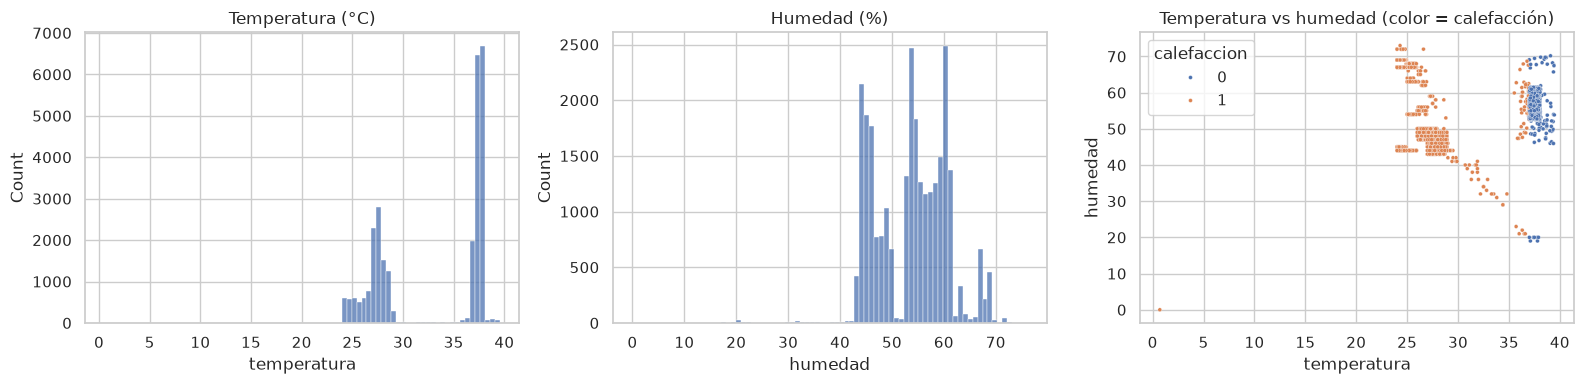

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(d.temperatura, bins=80, ax=ax[0]).set_title("Temperatura (°C)")
sns.histplot(d.humedad, bins=80, ax=ax[1]).set_title("Humedad (%)")
sns.scatterplot(data=d.sample(5000, random_state=0), x="temperatura", y="humedad", hue="calefaccion", s=8, ax=ax[2])
ax[2].set_title("Temperatura vs humedad (color = calefacción)"); plt.tight_layout()

In [6]:
print(pd.crosstab(pd.cut(d.temperatura, [-1, 5, 30, 35, 36.5, 38.5, 50]), [d.calefaccion, d.alarma]))

calefaccion       0           1     
alarma            0    1      0    1
temperatura                         
(-1.0, 5.0]       0    0      2    2
(5.0, 30.0]       7    0  11811    2
(30.0, 35.0]      0    0    112    0
(35.0, 36.5]      0    0     23  165
(36.5, 38.5]  14002  651      4  573
(38.5, 50.0]      0  183      0    0


**Hallazgos**

- No hay nulos ni duplicados; la frecuencia típica es de 1 lectura por segundo, con huecos entre sesiones de prueba.
- Hay **dos regímenes normales**: incubación (36.5–38.5 °C, foco regulando) y **precalentamiento** (20–35 °C con la calefacción encendida y la temperatura subiendo, sin alarma). El segundo es la maqueta real a temperatura ambiente.
- Las lecturas con `alarma = 1` son las que el firmware marcó fuera de umbral. Las lecturas con temperatura < 5 °C o humedad < 5 % son fallas del DHT.

Por eso no basta con un umbral fijo: 30 °C es normal si el foco está encendido calentando, pero es anómalo si está apagado. El modelo aprende esa relación conjunta entre sensores y actuadores.

## 2. Preprocesamiento y etiquetado

- **Features:** temperatura, humedad, estado de los 3 actuadores y la derivada por segundo de temperatura y humedad (`d_temp`, `d_hum`). Si dos lecturas están separadas más de 10 s la derivada se reinicia, para no confundir el cambio entre sesiones con un salto real.
- **Escalado:** `StandardScaler`. LOF usa distancias, así que sin escalar la humedad (rango ~50) dominaría a los actuadores (0/1).
- **Estrategia no supervisada:** se entrena **solo con lecturas normales** (`alarma = 0` y sin falla de sensor). Las etiquetas sirven únicamente para evaluar:
  - anomalías **reales**: lecturas con `alarma = 1` y fallas del sensor;
  - anomalías **simuladas** sobre lecturas reales: sobrecalentamiento con el foco pegado, enfriamiento con el foco quemado, humedad muy baja o alta, saltos bruscos y actuadores incoherentes.

In [7]:
d = agregar_derivadas(d)
falla = es_falla_sensor(d)
normales = d[(d.alarma == 0) & ~falla]
reales = d[(d.alarma == 1) | falla]
print(f"normales={len(normales)}  anomalías reales={len(reales)} (fallas de sensor={falla.sum()})")

mezcla = normales.sample(frac=1, random_state=1)
n = len(mezcla)
train, val, test_n = mezcla[: int(n * .70)], mezcla[int(n * .70): int(n * .85)], mezcla[int(n * .85):]
r = reales.sample(frac=1, random_state=1)
val_r, test_r = r[: len(r) // 2], r[len(r) // 2:]
val_s, _ = simular_anomalias(train, 400, seed=1)
test_s, tipos_test = simular_anomalias(train, 400, seed=2)

def armar(norm, *anom):
    X = pd.concat([norm, *anom])[FEATURES]
    y = np.r_[np.zeros(len(norm)), np.ones(sum(len(a) for a in anom))]
    return X, y

X_val, y_val = armar(val, val_r, val_s)
X_test, y_test = armar(test_n, test_r, test_s)
print("train", train.shape, "| val", X_val.shape, int(y_val.sum()), "anómalas | test", X_test.shape, int(y_test.sum()), "anómalas")

normales=25959  anomalías reales=1578 (fallas de sensor=4)


train (18171, 13) | val (5083, 7) 1189 anómalas | test (5083, 7) 1189 anómalas


## 3. Entrenamiento y evaluación

Se comparan dos algoritmos de detección de novedades de scikit-learn:

- **Isolation Forest:** aísla puntos con cortes aleatorios; es rápido, pero sus cortes son paralelos a los ejes.
- **Local Outlier Factor (`novelty=True`):** compara la densidad local de cada lectura con la de sus vecinos.

En los dos casos el umbral sobre el puntaje se elige en **validación** maximizando el F1, y las métricas finales se miden en **test**, un conjunto que el modelo no vio.

In [8]:
def evaluar(nombre, modelo):
    p = make_pipeline(StandardScaler(), modelo).fit(train[FEATURES])
    s_val, s_test = -p.score_samples(X_val), -p.score_samples(X_test)   # mayor = más anómalo
    pr, rc, th = precision_recall_curve(y_val, s_val)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    umbral = float(th[f1[:-1].argmax()])
    pred = s_test >= umbral
    return p, umbral, s_test, pred, {
        "modelo": nombre, "umbral": round(umbral, 4),
        "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred), "auc_roc": roc_auc_score(y_test, s_test)}

res = {
    "IsolationForest": evaluar("IsolationForest", IsolationForest(n_estimators=300, random_state=0)),
    "LOF": evaluar("LOF", LocalOutlierFactor(n_neighbors=35, novelty=True)),
}
tabla = pd.DataFrame([r[4] for r in res.values()]).set_index("modelo"); tabla

,umbral,precision,recall,f1,auc_roc
modelo,,,,,
IsolationForest,0.505,0.581,0.783,0.667,0.874
LOF,1.631,0.849,0.987,0.913,0.980


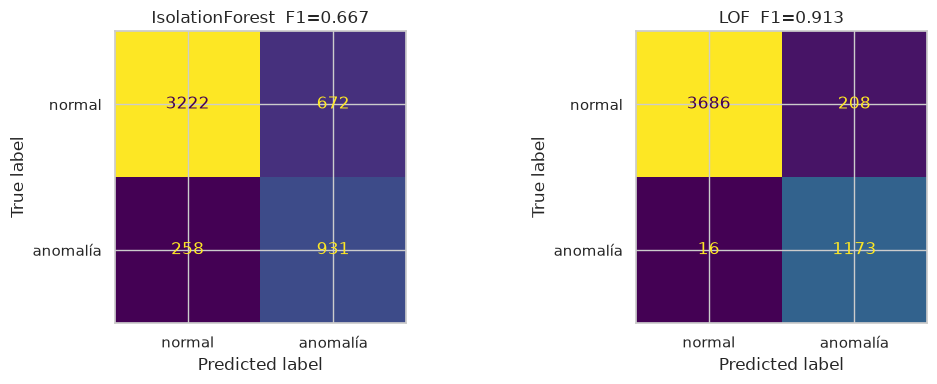

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nombre, r) in zip(ax, res.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, r[3]), display_labels=["normal", "anomalía"]).plot(ax=a, colorbar=False)
    a.set_title(f"{nombre}  F1={r[4]['f1']:.3f}")
plt.tight_layout(); plt.savefig("evidencias/matriz_confusion.png", dpi=120)

In [10]:
modelo, umbral, s_test, pred, met = res["LOF"]
print(classification_report(y_test, pred, target_names=["normal", "anomalía"], digits=3))
n_norm, n_real = len(test_n), len(test_r)
print("Recall en anomalías reales del histórico:", round(pred[n_norm:n_norm + n_real].mean(), 3))
print("Recall por tipo de anomalía simulada:")
print(pd.Series(pred[n_norm + n_real:]).groupby(tipos_test).mean().round(3).to_string())

              precision    recall  f1-score   support

      normal      0.996     0.947     0.971      3894
    anomalía      0.849     0.987     0.913      1189

    accuracy                          0.956      5083
   macro avg      0.923     0.967     0.942      5083
weighted avg      0.961     0.956     0.957      5083

Recall en anomalías reales del histórico: 0.995
Recall por tipo de anomalía simulada:
actuador_incoherente    1.000
enfriamiento            1.000
humedad_alta            1.000
humedad_baja            0.812
salto_brusco            1.000
sobrecalentamiento      1.000


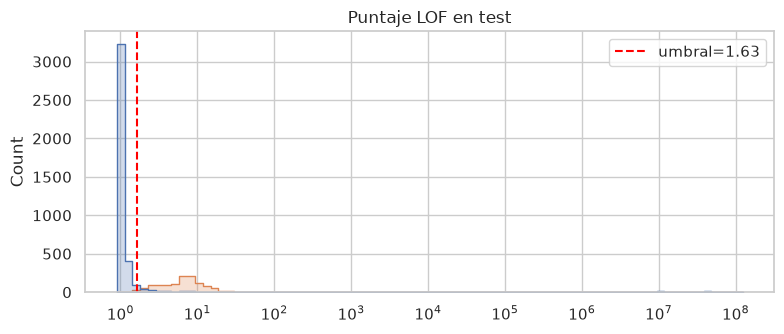

In [11]:
plt.figure(figsize=(8, 3.5))
sns.histplot(x=s_test, hue=np.where(y_test == 1, "anomalía", "normal"), bins=80, log_scale=(True, False), element="step")
plt.axvline(umbral, color="red", ls="--", label=f"umbral={umbral:.2f}"); plt.legend(); plt.title("Puntaje LOF en test")
plt.tight_layout(); plt.savefig("evidencias/distribucion_puntaje.png", dpi=120)

**Elección: LOF.** Supera a Isolation Forest en F1 y AUC y detecta casi todas las anomalías reales del histórico. Isolation Forest falla sobre todo en las fallas que **combinan** variables (enfriamiento con el foco apagado, actuadores incoherentes), porque sus cortes son paralelos a los ejes. LOF, en cambio, mide la distancia al comportamiento conocido en el espacio conjunto.

**Umbral:** puntaje LOF ≥ el umbral elegido en validación. Para no alarmar por una sola lectura ruidosa, el servicio además exige **3 lecturas anómalas seguidas** antes de publicar `anomalia: true` (configurable con `ML_CONSECUTIVAS`).

## 4. Guardado del modelo

In [12]:
joblib.dump(modelo, "modelo/modelo_lof.joblib")
meta = {"algoritmo": "LocalOutlierFactor(n_neighbors=35, novelty=True) + StandardScaler",
        "features": FEATURES, "umbral": umbral,
        "metricas_test": {k: round(float(v), 4) for k, v in met.items() if k != "modelo"},
        "comparacion": tabla.round(4).reset_index().to_dict("records"),
        "n_train": len(train), "n_test": int(len(y_test)), "anomalias_test": int(y_test.sum())}
json.dump(meta, open("modelo/meta.json", "w"), indent=2, ensure_ascii=False)
meta["metricas_test"]

{'umbral': 1.6314,
 'precision': 0.8494,
 'recall': 0.9865,
 'f1': 0.9128,
 'auc_roc': 0.9801}

In [13]:
# Prueba rápida del modelo cargado desde disco: una lectura normal y dos fallas.
m = joblib.load("modelo/modelo_lof.joblib")
casos = pd.DataFrame([
    dict(temperatura=37.5, humedad=57, calefaccion=0, ventilacion=0, rotacion=0, d_temp=0.0, d_hum=0.0),
    dict(temperatura=41.0, humedad=57, calefaccion=1, ventilacion=0, rotacion=0, d_temp=0.2, d_hum=0.0),
    dict(temperatura=37.5, humedad=20, calefaccion=0, ventilacion=0, rotacion=0, d_temp=0.0, d_hum=-2.0),
], index=["normal", "foco pegado", "humedad baja"])[FEATURES]
pd.DataFrame({"puntaje": -m.score_samples(casos), "anomalia": -m.score_samples(casos) >= umbral}, index=casos.index)

,puntaje,anomalia
normal,0.969,False
foco pegado,9.145,True
humedad baja,2.388,True
